# Hyperspectral Images (HSI)

This Notebook focuses on :

1. Reading hyperspectral image
2. Visualizing the bands of the Hyperspectral image
3. Visualizing ground truth of the image.
4. Extracting pixels of the HSI
5. Visualizing spectral signatures

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from tqdm import tqdm
import pandas as pd

### 1. Reading Hyperspectral Image 

**Indian_pines_corrected.mat** - The data set in .mat format

**Indian_pines_gt.mat** - The ground truth of the dataset in .mat format

Groundtruth classes for the Indian Pines scene and their respective samples number

In [3]:
path = "../dataset/Indian_pines_corrected (1).mat"

# Load the .mat file
data = loadmat(path)

# List all keys
print(data.keys())

# Access the hyperspectral image cube
cube = data['indian_pines_corrected'] 

print("Shape of the hyperspectral cube:", cube.shape)

dict_keys(['__header__', '__version__', '__globals__', 'indian_pines_corrected'])
Shape of the hyperspectral cube: (145, 145, 200)


### 2. Visualizing Bands of the Hyperspectral Image

In [4]:
def plot_band(dataset, band_no):
    plt.figure(figsize=(8, 6))
    #band_no = np.random.randint(dataset.shape[2])
    plt.imshow(dataset[:,:, band_no], cmap='jet')
    plt.title(f'Band-{band_no}', fontsize=14)
    plt.axis('off')
    plt.colorbar()
    plt.show()

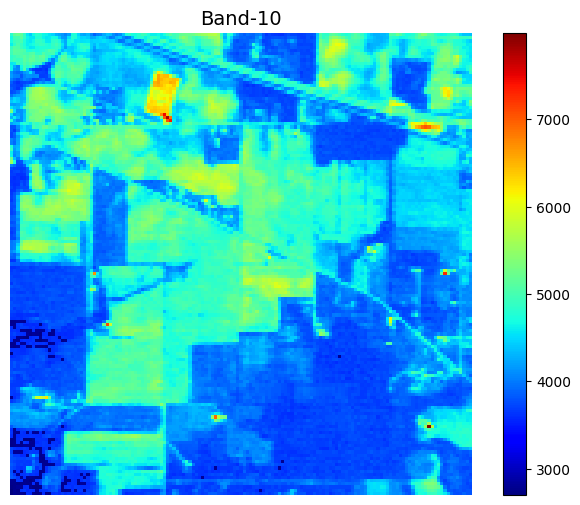

In [5]:
plot_band(cube, 10)


### 3. Visualizing Ground Truth Image

In [5]:
ground_truth_path = "../dataset/Indian_pines_gt.mat"

data = loadmat(ground_truth_path)
ground_truth = data['indian_pines_gt']

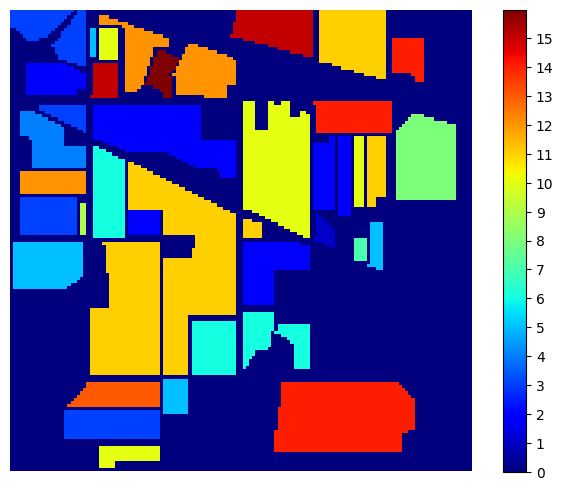

In [6]:
plt.figure(figsize=(8, 6))
plt.imshow(ground_truth, cmap='jet')
plt.axis('off')
plt.colorbar(ticks= range(0,16))
plt.show()

### 4. Extracting pixels of the HSI

In [7]:
def extract_pixels(dataset, ground_truth):
    df = pd.DataFrame()
    for i in tqdm(range(dataset.shape[2])):
        df = pd.concat([df, pd.DataFrame(dataset[:, :, i].ravel())], axis=1)
    df = pd.concat([df, pd.DataFrame(ground_truth.ravel())], axis=1)
    df.columns = [f'band-{i}' for i in range(1, 1+dataset.shape[2])]+['class']
    return df

In [8]:
pixels_df = extract_pixels(cube, ground_truth)
pixels_df.head()

100%|██████████| 200/200 [00:01<00:00, 169.51it/s]


,band-1,band-2,band-3,band-4,band-5,band-6,band-7,band-8,band-9,band-10,...,band-192,band-193,band-194,band-195,band-196,band-197,band-198,band-199,band-200,class
0,3172,4142,4506,4279,4782,5048,5213,5106,5053,4750,...,1094,1090,1112,1090,1062,1069,1057,1020,1020,3
1,2580,4266,4502,4426,4853,5249,5352,5353,5347,5065,...,1108,1104,1117,1091,1079,1085,1064,1029,1020,3
2,3687,4266,4421,4498,5019,5293,5438,5427,5383,5132,...,1111,1114,1114,1100,1065,1092,1061,1030,1016,3
3,2749,4258,4603,4493,4958,5234,5417,5355,5349,5096,...,1122,1108,1109,1109,1071,1088,1060,1030,1006,3
4,2746,4018,4675,4417,4886,5117,5215,5096,5098,4834,...,1110,1107,1112,1094,1072,1087,1052,1034,1019,3


- saving data to CSV file

In [14]:
pixels_df.to_csv('../dataset/pixels.csv', index=False)

### 5. Visualizing Spectral signature

In [9]:
def plot_signature(df,pixel_no = None):
    plt.figure(figsize=(12, 6))
    if pixel_no is None:pixel_no = np.random.randint(df.shape[0])
    plt.plot(range(1, 201), df.iloc[pixel_no, :-1].values.tolist(), 'b--', label= f'Class - {df.iloc[pixel_no, -1]}')
    plt.legend()
    plt.title(f'Pixel({pixel_no}) signature', fontsize=14)
    plt.xlabel('Band Number', fontsize=14)
    plt.ylabel('Pixel Intensity', fontsize=14)
    plt.show()

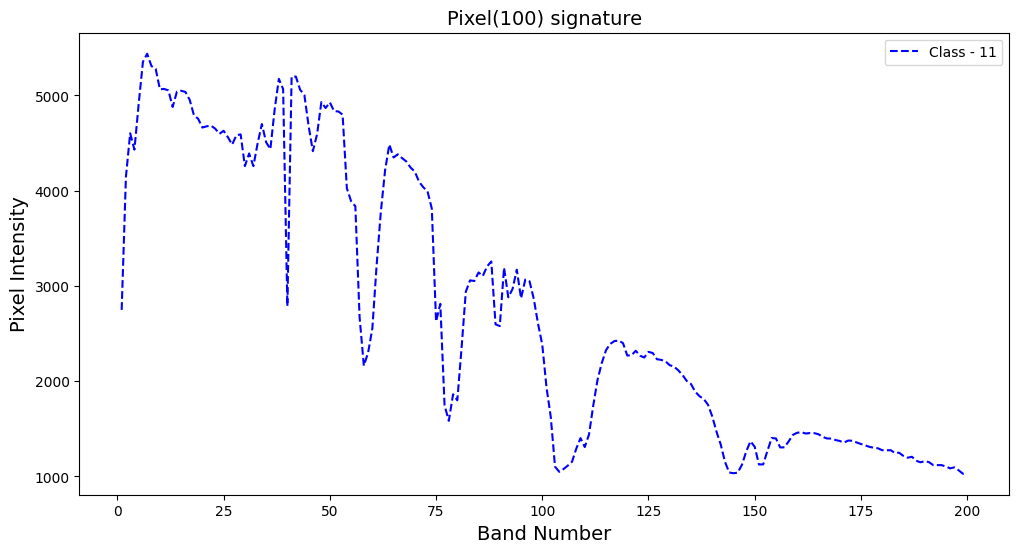

In [10]:
plot_signature(pixels_df,100)